# Regression in Scikit-learn

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [13]:
# 1. Dataset load karein
df = sns.load_dataset('titanic')
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


simple linear regression
2no variable numeric hoty h 

In [14]:
# Sirf age aur fare columns select karein (.copy() use karna best practice hai)
df_linear = df[['age', 'fare']].copy()

In [15]:
# 2. PEHLAY missing values ka percentage check karein
missing_percentage = (df_linear['age'].isnull().sum() / len(df_linear)) * 100
print(f"Missing values %: {missing_percentage:.2f}%")


Missing values %: 19.87%


In [16]:
# 3. Missing values ko mean se fill karein (df_linear ko directly update karein)
mean_age = df_linear['age'].mean()
df_linear['age'] = df_linear['age'].fillna(mean_age)

In [17]:
# 4. Ab check karein (ab yeh 0.00% aayega kyunke df_linear update ho chuka hai)
missing_after = (df_linear['age'].isnull().sum() / len(df_linear)) * 100
print(f"After filling: {missing_after:.2f}%")

After filling: 0.00%


In [18]:
Q1 = df_linear['fare'].quantile(0.25)
Q3 = df_linear['fare'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_linear = df_linear[(df_linear['fare'] >= lower_bound) & (df_linear['fare'] <= upper_bound)]
print(f"Rows after outlier removal: {len(df_linear)}")

Rows after outlier removal: 775


In [19]:
X = df_linear[['age']]   # Independent variable (Feature) - 2D array
y = df_linear['fare']    # Dependent variable (Target) - 1D array

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training data: {len(X_train)} rows")
print(f"Testing data: {len(X_test)} rows")

Training data: 620 rows
Testing data: 155 rows


In [21]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.05]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['age']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,15.68
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [22]:
y_pred = model.predict(X_test)

# Model Evaluate Karein

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("--- Model Performance ---")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")
print(f"Slope (m): {model.coef_[0]:.4f}")
print(f"Intercept (c): {model.intercept_:.4f}")

--- Model Performance ---
MAE: 12.27
RMSE: 16.09
R² Score: -0.0242
Slope (m): 0.0527
Intercept (c): 15.6770


#  Linear Regression Plot Banayein

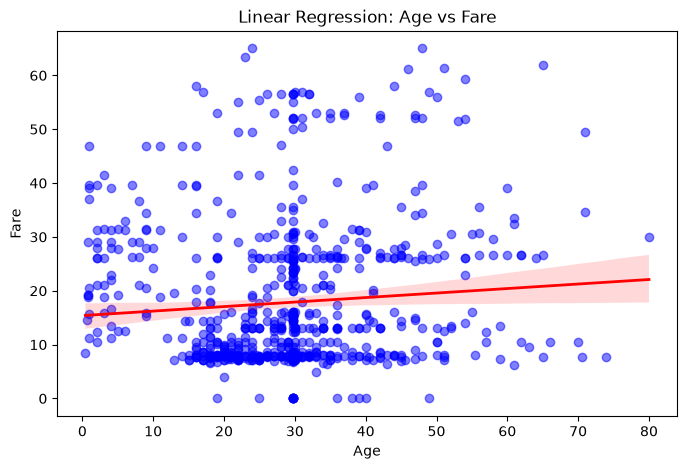

In [26]:
plt.figure(figsize=(8, 5))
sns.regplot(x='age', y='fare', data=df_linear,
            scatter_kws={'alpha': 0.5, 'color': 'blue'},
            line_kws={'color': 'red', 'linewidth': 2})
plt.title('Linear Regression: Age vs Fare')
plt.xlabel('Age')
plt.ylabel('Fare')
plt.show()

In [27]:
print("Total rows in our data:", len(X))
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

# Yeh check karein ke Train + Test = Total Data
print("Kya dono mil kar total bante hain?", X_train.shape[0] + X_test.shape[0] == len(X))

Total rows in our data: 775
X_train shape: (620, 1)
X_test shape: (155, 1)
Kya dono mil kar total bante hain? True
